In [ ]:
import pandas as pd
import glob
import os

files = glob.glob("dataset/**/*.csv", recursive=True)

for file in files:
    df = pd.read_csv(file)
    print(os.path.basename(file), df.shape)

 <h1> Check energy_mix_yearly.csv</h1>

In [ ]:
energy = pd.read_csv("sample_data/energy_mix_yearly.csv")

energy.head()

,year,country,iso3,region,coal_pct,oil_pct,gas_pct,nuclear_pct,hydro_pct,solar_pct,wind_pct,other_renewables_pct,renewables_total_pct,fossil_total_pct
0,2000,China,CHN,Asia,68.00,21.98,2.78,0.87,6.36,0.01,0.00,0.00,6.37,92.75
1,2001,China,CHN,Asia,67.64,21.35,3.36,0.97,6.46,0.00,0.04,0.17,6.68,92.36
2,2002,China,CHN,Asia,67.56,21.21,3.19,1.30,6.38,0.00,0.35,0.03,6.76,91.95
3,2003,China,CHN,Asia,67.69,20.71,3.24,1.30,6.33,0.07,0.33,0.34,7.06,91.64
4,2004,China,CHN,Asia,67.76,20.44,3.48,1.02,6.57,0.02,0.20,0.50,7.29,91.68


In [ ]:
energy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1350 entries, 0 to 1349
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  1350 non-null   int64  
 1   country               1350 non-null   object 
 2   iso3                  1350 non-null   object 
 3   region                1350 non-null   object 
 4   coal_pct              1350 non-null   float64
 5   oil_pct               1350 non-null   float64
 6   gas_pct               1350 non-null   float64
 7   nuclear_pct           1350 non-null   float64
 8   hydro_pct             1350 non-null   float64
 9   solar_pct             1350 non-null   float64
 10  wind_pct              1350 non-null   float64
 11  other_renewables_pct  1350 non-null   float64
 12  renewables_total_pct  1350 non-null   float64
 13  fossil_total_pct      1350 non-null   float64
dtypes: float64(10), int64(1), object(3)
memory usage: 147.8+ KB


In [ ]:
energy.columns.tolist()

['year',
 'country',
 'iso3',
 'region',
 'coal_pct',
 'oil_pct',
 'gas_pct',
 'nuclear_pct',
 'hydro_pct',
 'solar_pct',
 'wind_pct',
 'other_renewables_pct',
 'renewables_total_pct',
 'fossil_total_pct']

In [ ]:
energy.describe()

,year,coal_pct,oil_pct,gas_pct,nuclear_pct,hydro_pct,solar_pct,wind_pct,other_renewables_pct,renewables_total_pct,fossil_total_pct
count,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000
mean,2013.000000,15.358970,36.529304,25.293719,5.157615,7.880600,2.973963,2.747970,4.057570,17.660215,77.182059
std,7.791767,15.737703,7.962231,13.641831,6.444548,8.437632,2.552514,2.887144,3.022374,11.956569,12.704714
min,2000.000000,0.000000,10.780000,2.640000,0.000000,0.000000,0.000000,0.000000,0.000000,0.670000,40.810000
25%,2006.000000,3.817500,32.500000,14.390000,1.150000,2.100000,0.875000,0.460000,1.690000,7.432500,67.642500
50%,2013.000000,11.865000,35.500000,24.120000,2.545000,4.740000,2.520000,1.825000,3.860000,15.655000,77.820000
75%,2020.000000,23.890000,42.912500,37.357500,8.977500,9.935000,4.567500,4.130000,5.610000,23.397500,89.565000
max,2026.000000,75.450000,51.840000,56.120000,42.470000,35.280000,18.840000,15.370000,15.190000,51.490000,99.330000


Check target variable **Renewables_Total_Pct**

In [ ]:
energy["renewables_total_pct"].describe()

,renewables_total_pct
count,1350.000000
mean,17.660215
std,11.956569
min,0.670000
25%,7.432500
50%,15.655000
75%,23.397500
max,51.490000


In [ ]:
energy["renewables_total_pct"].isna().sum()
## (0) means no missing values

np.int64(0)

**RENEWABLE ENERGY TREND (Plot)**

In [ ]:
energy.columns.tolist()

['year',
 'country',
 'iso3',
 'region',
 'coal_pct',
 'oil_pct',
 'gas_pct',
 'nuclear_pct',
 'hydro_pct',
 'solar_pct',
 'wind_pct',
 'other_renewables_pct',
 'renewables_total_pct',
 'fossil_total_pct']

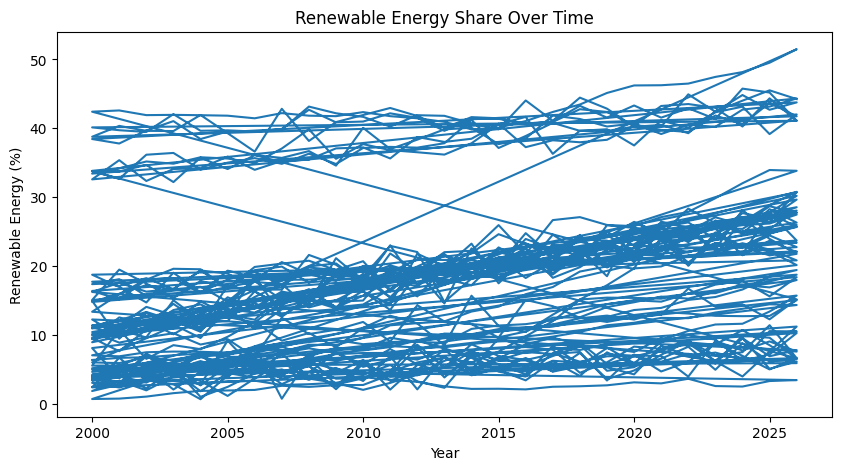

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    energy["year"],
    energy["renewables_total_pct"]
)

plt.xlabel("Year")
plt.ylabel("Renewable Energy (%)")
plt.title("Renewable Energy Share Over Time")

plt.show()

In [ ]:
[c for c in energy.columns
 if "coal" in c.lower() or
    "oil" in c.lower() or
    "gas" in c.lower() or
    "renew" in c.lower()]

['coal_pct',
 'oil_pct',
 'gas_pct',
 'other_renewables_pct',
 'renewables_total_pct']

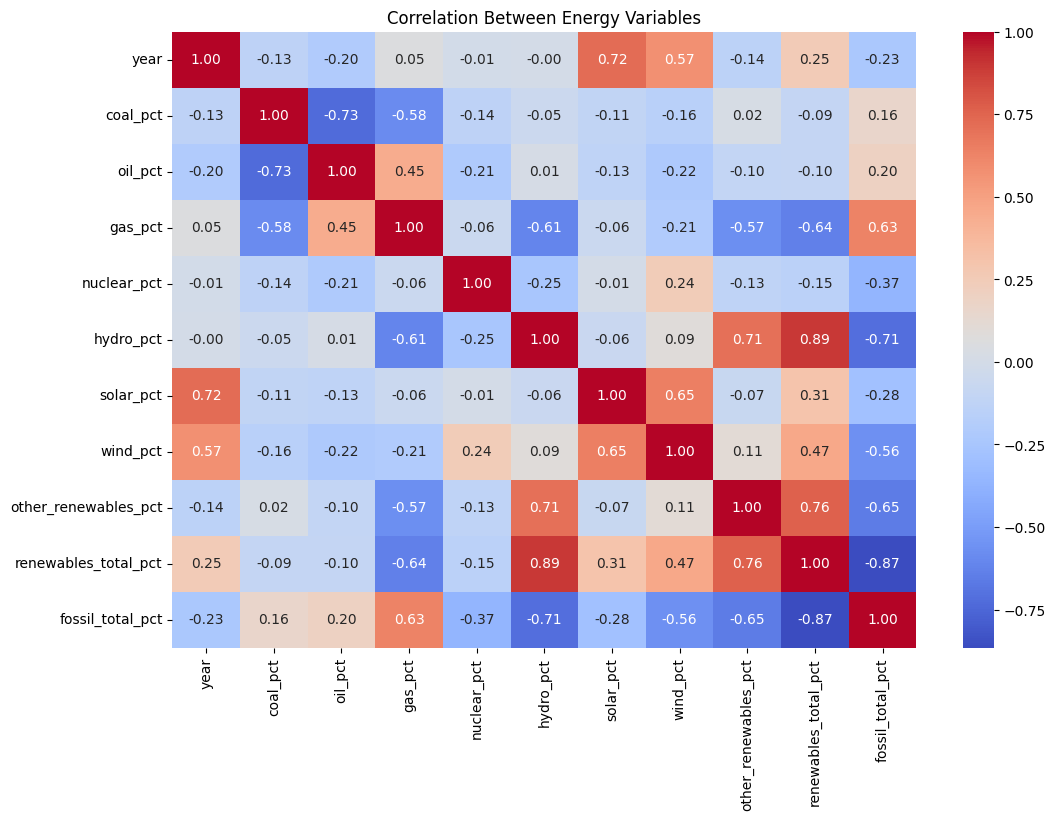

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_data = energy.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Energy Variables")
plt.show()

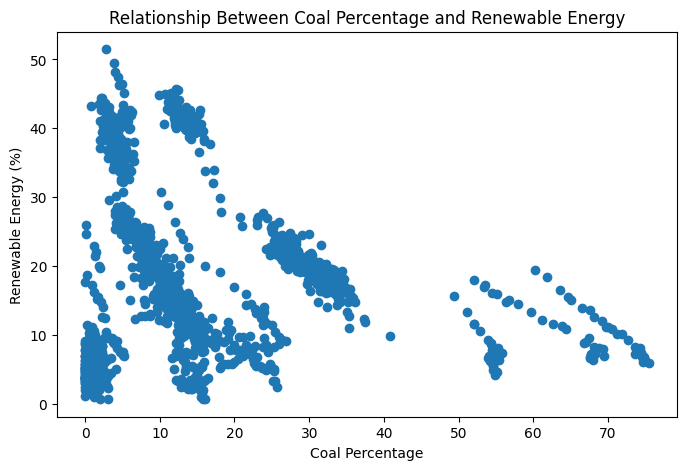

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    energy["coal_pct"], # Changed 'PREDICTOR_COLUMN' to 'coal_pct'
    energy["renewables_total_pct"]
)

plt.xlabel("Coal Percentage") # Updated label
plt.ylabel("Renewable Energy (%)")
plt.title("Relationship Between Coal Percentage and Renewable Energy") # Updated title

plt.show()

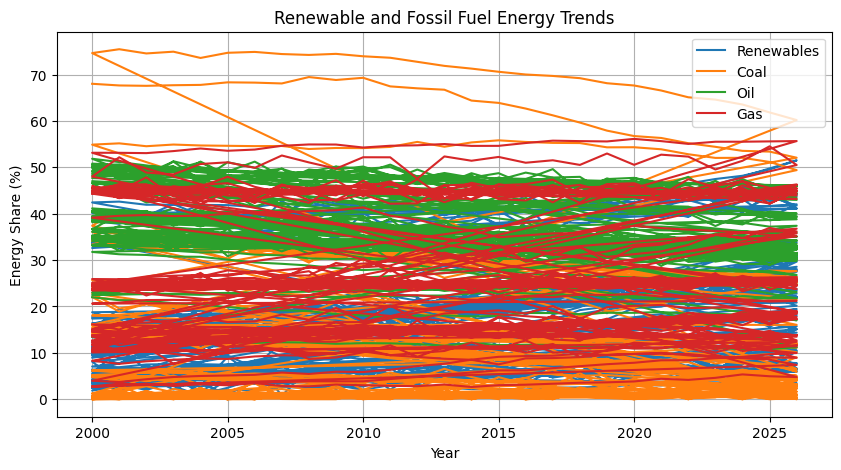

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(energy["year"], energy["renewables_total_pct"], label="Renewables")
plt.plot(energy["year"], energy["coal_pct"], label="Coal")
plt.plot(energy["year"], energy["oil_pct"], label="Oil")
plt.plot(energy["year"], energy["gas_pct"], label="Gas")

plt.xlabel("Year")
plt.ylabel("Energy Share (%)")
plt.title("Renewable and Fossil Fuel Energy Trends")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
energy[[
    "renewables_total_pct",
    "coal_pct",
    "oil_pct",
    "gas_pct"
]].describe()

,renewables_total_pct,coal_pct,oil_pct,gas_pct
count,1350.000000,1350.000000,1350.000000,1350.000000
mean,17.660215,15.358970,36.529304,25.293719
std,11.956569,15.737703,7.962231,13.641831
min,0.670000,0.000000,10.780000,2.640000
25%,7.432500,3.817500,32.500000,14.390000
50%,15.655000,11.865000,35.500000,24.120000
75%,23.397500,23.890000,42.912500,37.357500
max,51.490000,75.450000,51.840000,56.120000


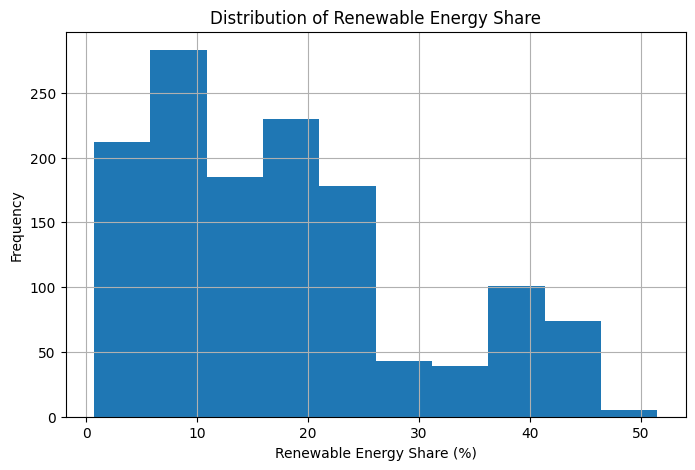

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    energy["renewables_total_pct"],
    bins=10
)

plt.xlabel("Renewable Energy Share (%)")
plt.ylabel("Frequency")
plt.title("Distribution of Renewable Energy Share")

plt.grid(True)
plt.show()